# Лабораторна робота №4. Метод опорних векторів
Горбач Ангеліна, ФІ-31

У цій лабораторній роботі я визначаю цінову категорію вживаного авто за його характеристиками. Порівнюю SVM із лінійним і RBF-ядром.

[Vehicle Dataset from CarDekho](https://www.kaggle.com/datasets/nehalbirla/vehicle-dataset-from-cardekho)

## 1. Очищення даних

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix


data = pd.read_csv("Car details v3.csv")
duplicate_count = int(data.duplicated().sum())
print("Початковий розмір:", data.shape)
print("Пропуски:\n", data.isna().sum().to_string())
data = data.drop_duplicates().copy()
invalid = ((data["selling_price"] <= 0) | (data["km_driven"] < 0)
           | (data["km_driven"] > 1_000_000) | (data["year"] < 1900)
           | (data["year"] > 2026)
           | data[["selling_price", "year", "km_driven"]].isna().any(axis=1))
invalid_count = int(invalid.sum())
data = data.loc[~invalid].copy()
print("Дублікати:", duplicate_count, "; некоректні записи:", invalid_count)
print("Після очищення:", data.shape)

Початковий розмір: (8128, 13)
Пропуски:
 name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          221
engine           221
max_power        215
torque           222
seats            221
Дублікати: 1202 ; некоректні записи: 2
Після очищення: (6924, 13)


## 2. Ознаки та поділ даних

Використовую ті самі межі цін, що й у лабораторній №2Б. До низького класу відношу авто дешевші за 300 000, до середнього — від 300 000 включно до 550 000, а до високого — від 550 000 включно. Ціну використовую тільки для визначення класу авто.

З назви авто виділяю марку, а з текстових характеристик дістаю числа. Показники в км/л і км/кг залишаю в окремих стовпцях. Для навчання беру 70% даних, для тесту — 30%. Частки цінових класів в обох вибірках приблизно однакові.

In [2]:
def first_number(value):
    if pd.isna(value):
        return np.nan
    match = re.search(r"\d+(?:\.\d+)?", str(value))
    return float(match.group()) if match else np.nan


def torque_in_nm(value):
    number = first_number(value)
    return number * 9.80665 if "kgm" in str(value).lower() else number


def get_features(rows):
    features = rows[["year", "km_driven", "fuel", "seller_type", "transmission", "owner", "seats"]].copy()
    features["brand"] = rows["name"].str.split().str[0]
    mileage_text = rows["mileage"].astype("string").str.lower().str.strip()
    mileage_number = rows["mileage"].map(first_number)
    # Keep different mileage units in separate numeric features.
    features["mileage_kmpl"] = mileage_number.where(mileage_text.str.endswith("kmpl", na=False))
    features["mileage_kmkg"] = mileage_number.where(mileage_text.str.endswith("km/kg", na=False))
    features["engine_cc"] = rows["engine"].map(first_number)
    features["max_power_bhp"] = rows["max_power"].map(first_number)
    features["torque_nm"] = rows["torque"].map(torque_in_nm)
    for column in ["mileage_kmpl", "mileage_kmkg", "engine_cc", "max_power_bhp", "torque_nm", "seats"]:
        features.loc[features[column] <= 0, column] = np.nan
    return features


class_names = ["низька", "середня", "висока"]
price_limits = [300000, 550000]
X_raw = get_features(data)
y = np.searchsorted(price_limits, data["selling_price"].to_numpy(), side="right")
train_indices, test_indices = train_test_split(
    np.arange(len(data)), test_size=0.3, random_state=42, stratify=y)
X_train = X_raw.iloc[train_indices].copy()
X_test = X_raw.iloc[test_indices].copy()
y_train, y_test = y[train_indices], y[test_indices]
counts = pd.DataFrame({"Навчання": np.bincount(y_train, minlength=3),
                       "Тест": np.bincount(y_test, minlength=3)}, index=class_names)
print(counts.to_string())
print(f"Навчання: {len(y_train)}, тест: {len(y_test)}")

         Навчання  Тест
низька       1573   675
середня      1584   679
висока       1689   724
Навчання: 4846, тест: 2078


## 3. Підготовка ознак

Якщо в числовому стовпці є пропуски, заповнюю їх медіаною цього стовпця. Потім масштабую числові ознаки, щоб, наприклад, пробіг не мав більшого впливу лише через те, що вимірюється тисячами кілометрів. Категорії перетворюю на стовпці з нулями й одиницями за допомогою One-Hot.

Усе це роблю через Pipeline. На кожному кроці кросвалідації медіани, параметри масштабування та список категорій визначаю лише за тією частиною даних, на якій навчається модель.

In [3]:
numeric_columns = ["year", "km_driven", "seats", "mileage_kmpl", "mileage_kmkg",
                   "engine_cc", "max_power_bhp", "torque_nm"]
category_columns = ["brand", "fuel", "seller_type", "transmission", "owner"]


def make_pipeline():
    numeric = Pipeline([("fill", SimpleImputer(strategy="median")),
                        ("scale", StandardScaler())])
    categorical = Pipeline([("fill", SimpleImputer(strategy="most_frequent")),
                            ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    preparation = ColumnTransformer([("num", numeric, numeric_columns),
                                     ("cat", categorical, category_columns)])
    return Pipeline([("prepare", preparation), ("svm", SVC(cache_size=256))])

## 4. Добір ядра і параметрів

Порівнюю лінійне та RBF-ядра. Параметр C визначає, наскільки сильно модель штрафує точки за порушення відступу. Для RBF також підбираю gamma. Що більше його значення, то на меншій відстані від точки відчутний її вплив.

Перевіряю 15 комбінацій параметрів. Для кожної тричі навчаю модель на двох частинах навчальної вибірки й перевіряю її на третій. Обираю комбінацію з найвищим середнім macro F1. У цій метриці всі три класи мають однакову вагу.

  Ядро     C gamma  CV macro F1  CV std
   rbf 100.0  0.01       0.8301  0.0028
   rbf   1.0 scale       0.8252  0.0025
   rbf  10.0 scale       0.8252  0.0048
   rbf   1.0   0.1       0.8251  0.0020
   rbf  10.0  0.01       0.8248  0.0045
   rbf  10.0   0.1       0.8231  0.0050
   rbf 100.0 scale       0.8185  0.0065
   rbf 100.0   0.1       0.8176  0.0083
   rbf 100.0 0.001       0.8129  0.0071
   rbf   1.0  0.01       0.8076  0.0081
linear   0.1     —       0.8066  0.0083
linear   1.0     —       0.8061  0.0068
linear  10.0     —       0.8061  0.0043
   rbf  10.0 0.001       0.8033  0.0087
   rbf   1.0 0.001       0.7634  0.0061
Обрана модель: {'svm__C': 100, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}


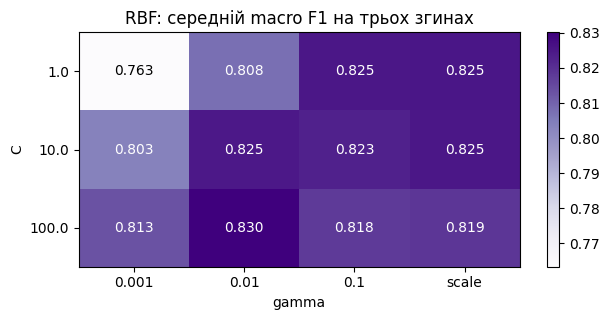

In [4]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
parameter_grid = [
    {"svm__kernel": ["linear"], "svm__C": [0.1, 1, 10]},
    {"svm__kernel": ["rbf"], "svm__C": [1, 10, 100],
     "svm__gamma": [0.001, 0.01, 0.1, "scale"]}]
search = GridSearchCV(make_pipeline(), parameter_grid, scoring="f1_macro",
                      cv=cv, refit=False, n_jobs=2, error_score="raise")
search.fit(X_train, y_train)
cv_results = pd.DataFrame(search.cv_results_)
cv_table = pd.DataFrame({
    "Ядро": [p["svm__kernel"] for p in cv_results["params"]],
    "C": [p["svm__C"] for p in cv_results["params"]],
    "gamma": [str(p.get("svm__gamma", "—")) for p in cv_results["params"]],
    "CV macro F1": cv_results["mean_test_score"],
    "CV std": cv_results["std_test_score"]})
print(cv_table.sort_values("CV macro F1", ascending=False).round(4).to_string(index=False))
best_indices = {kernel: cv_table.loc[cv_table["Ядро"] == kernel, "CV macro F1"].idxmax()
                for kernel in ["linear", "rbf"]}
best_index = cv_table["CV macro F1"].idxmax()
selected_kernel = cv_table.loc[best_index, "Ядро"]
print("Обрана модель:", cv_results.loc[best_index, "params"])

fig, ax = plt.subplots(figsize=(6.5, 3.3))
rbf_scores = cv_table[cv_table["Ядро"] == "rbf"].pivot(index="C", columns="gamma", values="CV macro F1")
rbf_scores = rbf_scores.reindex(columns=["0.001", "0.01", "0.1", "scale"])
im = ax.imshow(rbf_scores, cmap="Purples", vmin=rbf_scores.min().min(), vmax=rbf_scores.max().max(), aspect="auto")
ax.set_xticks(range(4), rbf_scores.columns)
ax.set_yticks(range(3), [str(v) for v in rbf_scores.index])
for i in range(3):
    for j in range(4):
        value = rbf_scores.iloc[i, j]
        ax.text(j, i, f"{value:.3f}", ha="center", va="center", color="white" if value > (rbf_scores.min().min()+rbf_scores.max().max())/2 else "black")
ax.set(xlabel="gamma", ylabel="C", title="RBF: середній macro F1 на трьох згинах")
fig.colorbar(im, ax=ax)
fig.tight_layout()
plt.show()

## 5. Результати

Після добору параметрів навчаю обидві моделі на всій навчальній вибірці. Потім перевіряю їх на тих самих тестових записах, щоб порівняти результати. Частку неправильних прогнозів обчислюю як `1 - accuracy`.


linear: {'svm__C': 0.1, 'svm__kernel': 'linear'}
              precision    recall  f1-score   support

      низька     0.8775    0.8489    0.8630       675
     середня     0.6925    0.7099    0.7011       679
      висока     0.8354    0.8412    0.8383       724

    accuracy                         0.8008      2078
   macro avg     0.8018    0.8000    0.8008      2078
weighted avg     0.8024    0.8008    0.8015      2078


rbf: {'svm__C': 100, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}
              precision    recall  f1-score   support

      низька     0.8864    0.8667    0.8764       675
     середня     0.7504    0.7570    0.7537       679
      висока     0.8759    0.8867    0.8813       724

    accuracy                         0.8378      2078
   macro avg     0.8375    0.8368    0.8371      2078
weighted avg     0.8383    0.8378    0.8380      2078

  Ядро  CV macro F1  Train accuracy  Test accuracy  Train error  Test error  Test macro F1  Опорних векторів
linear       0.

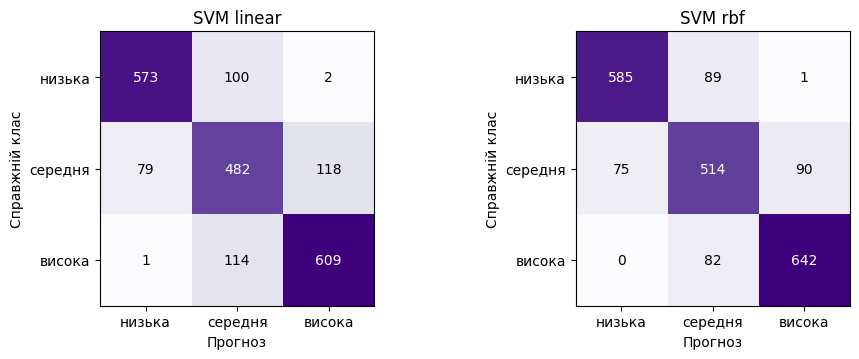

In [5]:
models = {}
results = []
for kernel, index in best_indices.items():
    model = make_pipeline().set_params(**cv_results.loc[index, "params"])
    model.fit(X_train, y_train)
    train_prediction = model.predict(X_train)
    test_prediction = model.predict(X_test)
    train_accuracy = accuracy_score(y_train, train_prediction)
    test_accuracy = accuracy_score(y_test, test_prediction)
    svm = model.named_steps["svm"]
    results.append({"Ядро": kernel, "CV macro F1": float(cv_table.loc[index, "CV macro F1"]),
                    "Train accuracy": train_accuracy, "Test accuracy": test_accuracy,
                    "Train error": 1-train_accuracy, "Test error": 1-test_accuracy,
                    "Test macro F1": f1_score(y_test, test_prediction, average="macro"),
                    "Опорних векторів": len(svm.support_)})
    models[kernel] = model
    print(f"\n{kernel}: {cv_results.loc[index, 'params']}")
    print(classification_report(y_test, test_prediction, target_names=class_names, digits=4, zero_division=0))
result_table = pd.DataFrame(results)
print(result_table.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.7))
for ax, (kernel, model) in zip(axes, models.items()):
    matrix = confusion_matrix(y_test, model.predict(X_test), labels=[0, 1, 2])
    ax.imshow(matrix, cmap="Purples")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, str(matrix[i, j]), ha="center", va="center", color="white" if matrix[i,j] > matrix.max()/2 else "black")
    ax.set_xticks(range(3), class_names)
    ax.set_yticks(range(3), class_names)
    ax.set(xlabel="Прогноз", ylabel="Справжній клас", title=f"SVM {kernel}")
fig.tight_layout()
plt.show()

## 6. Опорні вектори

In [6]:
svm = models[selected_kernel].named_steps["svm"]
support = pd.Series(svm.n_support_, index=class_names)
print(support.to_string())
print("Усього опорних векторів:", support.sum())

низька     481
середня    992
висока     506
Усього опорних векторів: 1979


За результатами кросвалідації обрала модель з RBF-ядром і параметрами `C=100` та `gamma=0.01`. На тесті вона правильно визначила цінову категорію 1741 із 2078 авто. Це 83,78% правильних прогнозів. Модель із лінійним ядром отримала 80,08%.

На навчальних даних модель з RBF помилилася у 14,16% випадків, а на тестових — у 16,22%. Значення macro F1 на тесті становить 0,8371.

З матриці помилок видно, що модель найчастіше плутала середню цінову категорію з низькою або високою. Між двома крайніми категоріями була лише одна помилка.

## 7. Приклад XOR

Лінійне ядро правильно класифікує 2 з 4 навчальних точок, RBF — усі 4. Чорним кільцем позначені опорні вектори.

XOR, linear: 50%
XOR, rbf: 100%


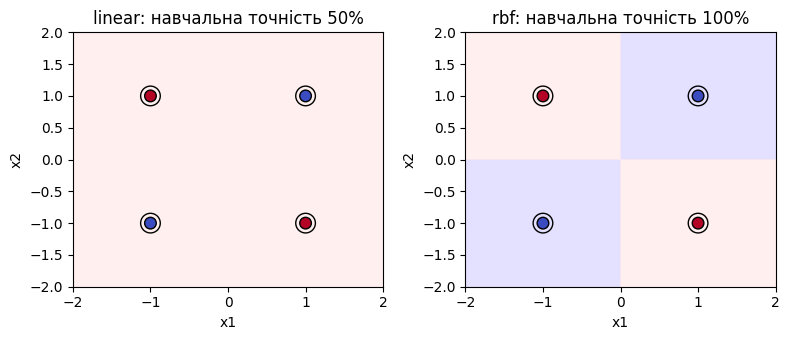

In [7]:
X_xor = np.array([[-1, -1], [-1, 1], [1, -1], [1, 1]], dtype=float)
y_xor = np.array([0, 1, 1, 0])
x1, x2 = np.meshgrid(np.linspace(-2, 2, 200), np.linspace(-2, 2, 200))
grid = np.column_stack([x1.ravel(), x2.ravel()])
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
for ax, kernel in zip(axes, ["linear", "rbf"]):
    xor_model = SVC(kernel=kernel, C=10, gamma=1).fit(X_xor, y_xor)
    prediction = xor_model.predict(grid).reshape(x1.shape)
    ax.contourf(x1, x2, prediction, levels=[-0.5, 0.5, 1.5], colors=["#D9D3FF", "#FFE9E9"], alpha=0.7)
    ax.scatter(X_xor[:, 0], X_xor[:, 1], c=y_xor, cmap="coolwarm", edgecolors="black", s=70)
    support = xor_model.support_vectors_
    ax.scatter(support[:, 0], support[:, 1], s=200, facecolors="none", edgecolors="black")
    score = accuracy_score(y_xor, xor_model.predict(X_xor))
    ax.set(title=f"{kernel}: навчальна точність {score:.0%}", xlabel="x1", ylabel="x2")
    print(f"XOR, {kernel}: {score:.0%}")
fig.tight_layout()
plt.show()

# Контрольні питання
**Як розв’язати XOR за допомогою SVM?**
Точки XOR розташовані так, що однією прямою їх не розділити. Тут можна використати RBF або поліноміальне ядро другого степеня. Якщо координати точок дорівнюють ±1, можна ще додати ознаку x1 * x2. Для одного класу добуток буде додатним, а для іншого — від’ємним.

**Що таке опорний вектор?**
Це точка з навчальної вибірки, яка має ненульовий коефіцієнт у функції рішення SVM. Саме такі точки визначають, де проходитиме межа між класами.

**Як обирати параметри?**
Перевіряю кілька варіантів на навчальних даних за допомогою кросвалідації й обираю той, у якого найвищий середній macro F1. Для RBF підбираю C і gamma. Якщо використовую поліноміальне ядро, враховую ще й степінь degree.

**Що показують атрибути SVC?**
За support_ можна знайти опорні вектори в навчальній вибірці, а в support_vectors_ — подивитися їхні координати. Атрибут n_support_ показує, скільки опорних векторів є в кожному класі. У dual_coef_ зберігаються коефіцієнти при опорних векторах, а в intercept_ — вільні члени функцій рішення. Для лінійного ядра в coef_ можна подивитися ваги ознак.